# PhishGuard-ML: 02 - Preprocessing and Feature Selection

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
import joblib
import os

## 1. Load the Dataset

In [2]:
df = pd.read_csv("data/phishing_websites.csv")
print("Dataset shape:", df.shape)

X = df.drop(columns=["Result"])
y = df["Result"]

Dataset shape: (11055, 31)


## 2. Train / Test Split

In [3]:
# 80% training, 20% testing, stratified
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

X_train shape: (8844, 30)
X_test shape: (2211, 30)


## 3. Feature Selection (Mutual Information)

In [4]:
# Compute mutual information scores
scores = mutual_info_classif(X_train, y_train, discrete_features=True, random_state=42)
importance = pd.Series(scores, index=X_train.columns).sort_values(ascending=False)

print("Top 10 features by Mutual Information:")
print(importance.head(10))

Top 10 features by Mutual Information:
sslfinal_state                0.346940
url_of_anchor                 0.332110
prefix_suffix                 0.083770
web_traffic                   0.078017
having_sub_domain             0.075735
links_in_tags                 0.032374
request_url                   0.031549
sfh                           0.026568
domain_registration_length    0.025265
google_index                  0.007444
dtype: float64


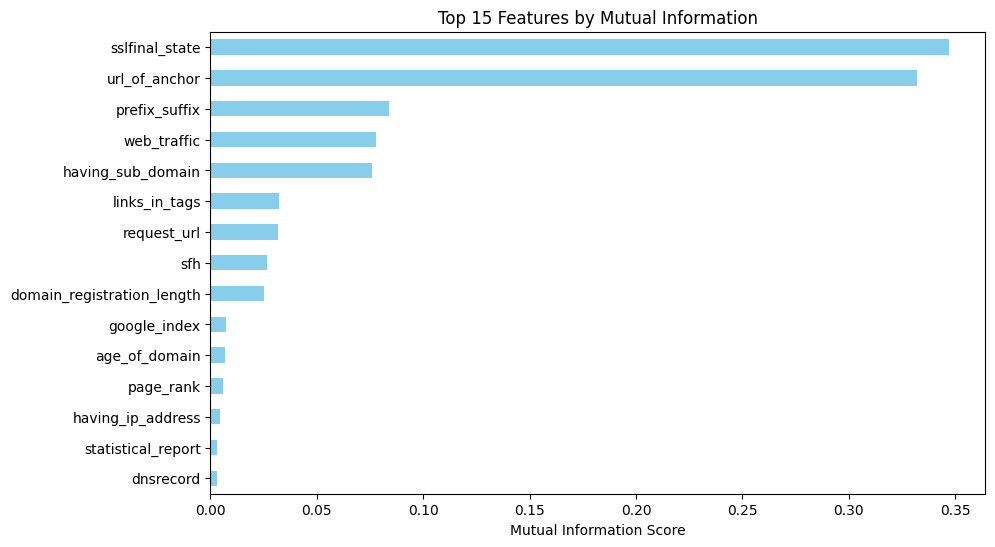

In [5]:
# Visualizing feature importance
plt.figure(figsize=(10, 6))
importance.head(15).plot(kind='barh', color='skyblue')
plt.title('Top 15 Features by Mutual Information')
plt.xlabel('Mutual Information Score')
plt.gca().invert_yaxis()
plt.show()

## 4. Save Preprocessed Data

In [6]:
# We will save the train and test splits so we can use them in the model training notebook.
# This ensures consistency across notebooks.

os.makedirs("data", exist_ok=True)
X_train.to_csv("data/X_train.csv", index=False)
X_test.to_csv("data/X_test.csv", index=False)
y_train.to_csv("data/y_train.csv", index=False)
y_test.to_csv("data/y_test.csv", index=False)

# Save feature importance
importance.to_csv("data/feature_importance.csv")

print("Data splits saved successfully.")

Data splits saved successfully.
